# Class 4: Dictionaries, annotation, and validation

This notebook builds a small dictionary for **employment attention**, checks it against a transparent codebook, and inspects the mistakes. The data are invented teaching examples, so we can see every decision clearly.


## The measurement task

We do not observe a concept directly. We define a rule that turns text into a label. That rule may be useful, but it can make predictable errors. The point of validation is to find and understand them.


In [1]:
from pathlib import Path
import csv
import re

def data_path(name):
    candidates = [
        Path("data") / name,
        Path("meeting_slides/meeting_04/data") / name,
    ]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(f"Could not find {name}. Run this notebook from meeting_04 or the repository root.")

with data_path("employment_examples.csv").open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

for row in rows:
    row["reference_label"] = int(row["reference_label"])

development_rows = [row for row in rows if row["split"] == "development"]
test_rows = [row for row in rows if row["split"] == "test"]
print(f"Loaded {len(rows)} annotated sentences: {len(development_rows)} for development and {len(test_rows)} held out for testing.")
print(rows[0]["text"])


Loaded 20 annotated sentences: 14 for development and 6 held out for testing.
The administration announced a programme to create 40,000 jobs in manufacturing.


## Before this notebook: corpus retrieval

These twenty sentences have already been selected. In a real project, a search string or database query often determines which texts enter the corpus. That query should be checked separately: a narrow query can miss relevant texts, while a broad query can retrieve irrelevant material.

This notebook focuses on the next step: measuring employment attention within the retrieved texts.


## Read the codebook first

The codebook in `CODEBOOK.md` defines the unit as a sentence. It includes paid employment, unemployment, hiring, job loss, labour-market indicators, and employment-related training. It excludes technical jobs, `job` as a task, and `employ` meaning use.

The reference labels below follow that codebook. We use the development set to inspect errors and revise the dictionary. The test set remains held out until the final evaluation.


In [2]:
for row in development_rows:
    label = "employment" if row["reference_label"] else "not employment"
    print(f"{row['id']:>2}. [{label:14}] {row['text']}")


 1. [employment    ] The administration announced a programme to create 40,000 jobs in manufacturing.
 2. [employment    ] The new tax credit is expected to encourage firms to hire workers.
 4. [employment    ] The factory closure will eliminate 600 local jobs.
 5. [employment    ] The proposal would raise the minimum wage for low-paid workers.
 7. [employment    ] The budget funds a job-training partnership with local colleges.
 9. [not employment] The overnight job submitted to the computing cluster without errors.
10. [not employment] This small engine does the job in under a second.
12. [not employment] The school hired a new principal after a long search.
13. [not employment] Workers repaired the bridge before the winter storms arrived.
14. [not employment] The President praised the hard work of volunteers in every community.
15. [employment    ] The measure is not expected to reduce unemployment this year.
16. [not employment] A worker process failed and the job was restarted aut

## Formalizing a dictionary rule

Let $d=(w_1,\ldots,w_n)$ be a text of $n$ tokens and $D$ a dictionary. For exact token matching, the count is

$$
c_D(d)=\sum_{i=1}^{n}\mathbf{1}\{w_i\in D\}.
$$

Here $\mathbf{1}\{\cdot\}$ equals 1 when the condition is true and 0 otherwise.

**Binary classification.** Apply a threshold $\tau$:

$$
\hat y_D(d;\tau)=\mathbf{1}\{c_D(d)\geq\tau\}.
$$

For example, $\tau=1$ labels a text positive when at least one dictionary term occurs. A phrase or regex dictionary uses a count of qualifying pattern matches in place of the exact-token count.

**Continuous measurement.** Keep the count, or normalize by length:

$$
r_D(d)=\frac{c_D(d)}{n}.
$$

For a weighted dictionary, assign weight $a_w$ to each term and zero to words outside the dictionary:

$$
s_D(d)=\sum_{i=1}^{n}a_{w_i}.
$$

This gives a continuous score, which can be used as a variable in a regression. Constructing the score does not itself fit a regression model.

**Positive-negative sentiment classification.** With weights $+1$ for positive terms and $-1$ for negative terms,

$$
s_{\mathrm{sent}}(d)=c_{D_+}(d)-c_{D_-}(d),
\qquad
\hat y_{\mathrm{sent}}(d)=\mathbf{1}\{s_{\mathrm{sent}}(d)>0\}.
$$

This is the rule used below for Rotten Tomatoes. A zero score is assigned to the negative class, so the tie rule is explicit.


## A first dictionary

This baseline looks for a few obvious surface forms. Word boundaries (`\b`) stop `job` from matching an arbitrary part of a longer word.


In [3]:
baseline_pattern = re.compile(
    r"\b(job|jobs|employment|unemployment|hire|hiring|hired|worker|workers|wage|wages)\b",
    re.IGNORECASE,
)

def label_with(pattern, text):
    return int(bool(pattern.search(text)))

for row in rows:
    row["baseline"] = label_with(baseline_pattern, row["text"])

print("Baseline terms:", baseline_pattern.pattern)


Baseline terms: \b(job|jobs|employment|unemployment|hire|hiring|hired|worker|workers|wage|wages)\b


## Counts, rates, and labels

The same matches can produce different data. A raw count records how often a term appears. A rate divides that count by the number of tokens. A binary label says only whether a match occurred.

Here we calculate all three, even though our validation task uses the binary label.


In [4]:
def token_count(text):
    return len(re.findall(r"[a-z]+", text.lower()))

for row in development_rows:
    row["baseline_count"] = len(baseline_pattern.findall(row["text"]))
    row["tokens"] = token_count(row["text"])
    row["baseline_rate_per_100"] = 100 * row["baseline_count"] / row["tokens"]

for row in development_rows[:5]:
    print(f"{row['id']:>2}. count={row['baseline_count']}, tokens={row['tokens']}, rate per 100={row['baseline_rate_per_100']:.1f}, label={row['baseline']}")


 1. count=1, tokens=10, rate per 100=10.0, label=1
 2. count=2, tokens=12, rate per 100=16.7, label=1
 4. count=1, tokens=7, rate per 100=14.3, label=1
 5. count=2, tokens=11, rate per 100=18.2, label=1
 7. count=1, tokens=10, rate per 100=10.0, label=1


## Score the rule

Let $TP$, $FP$, $FN$, and $TN$ denote the four cells of the confusion matrix. We will calculate

$$
\text{precision}=\frac{TP}{TP+FP},\qquad
\text{recall}=\frac{TP}{TP+FN},\qquad
\text{F1}=2\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}.
$$


In [5]:
def evaluate(prediction_key, subset):
    tp = sum(r[prediction_key] == 1 and r["reference_label"] == 1 for r in subset)
    fp = sum(r[prediction_key] == 1 and r["reference_label"] == 0 for r in subset)
    fn = sum(r[prediction_key] == 0 and r["reference_label"] == 1 for r in subset)
    tn = sum(r[prediction_key] == 0 and r["reference_label"] == 0 for r in subset)
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": precision, "recall": recall, "F1": f1}

def show_metrics(metrics, positive_label="employment", negative_label="not employment"):
    print(f"                Human {positive_label:<14} Human {negative_label}")
    print(f"Dictionary match       {metrics['TP']:>2}                    {metrics['FP']:>2}")
    print(f"No dictionary match    {metrics['FN']:>2}                    {metrics['TN']:>2}")
    print()
    print(f"Precision: {metrics['precision']:.3f}")
    print(f"Recall:    {metrics['recall']:.3f}")
    print(f"F1:        {metrics['F1']:.3f}")

baseline_metrics = evaluate("baseline", development_rows)
show_metrics(baseline_metrics)


                Human employment     Human not employment
Dictionary match        6                     5
No dictionary match     1                     2

Precision: 0.545
Recall:    0.857
F1:        0.667


## Inspect the errors

Metrics tell us how much the dictionary disagrees with the reference labels. The passages tell us why. Read both the false positives and false negatives before changing a rule.


In [6]:
def show_errors(prediction_key, subset):
    false_positives = [r for r in subset if r[prediction_key] == 1 and r["reference_label"] == 0]
    false_negatives = [r for r in subset if r[prediction_key] == 0 and r["reference_label"] == 1]
    print("FALSE POSITIVES")
    for r in false_positives:
        print(f"- {r['text']}")
    print()
    print("FALSE NEGATIVES")
    for r in false_negatives:
        print(f"- {r['text']}")

show_errors("baseline", development_rows)


FALSE POSITIVES
- The overnight job submitted to the computing cluster without errors.
- This small engine does the job in under a second.
- The school hired a new principal after a long search.
- Workers repaired the bridge before the winter storms arrived.
- A worker process failed and the job was restarted automatically.

FALSE NEGATIVES
- The task force will work with employers to expand apprenticeships.


## Revise the dictionary using the codebook

The expanded rule adds explicit labour-market terms and phrase patterns. It also removes generic `worker` from the single-word list because the codebook says that a person doing a task is not necessarily an employment discussion.

This is one defensible revision, not the only possible one. A more demanding project would develop the rule on one annotated sample and evaluate it on a fresh sample.


In [7]:
expanded_pattern = re.compile(
    r"\b(jobs?|jobless|employment|unemployment|unemployed|hiring|hired|layoffs?|"
    r"vacancies|wages?|paychecks?|employers?|apprenticeships?)\b|"
    r"\b(find|without|secure) work\b|\bhire workers\b|\bhiring workers\b|"
    r"\bhours worked\b|\bdisplaced workers\b|\blow-paid workers\b",
    re.IGNORECASE,
)

for row in rows:
    row["expanded"] = label_with(expanded_pattern, row["text"])

expanded_metrics = evaluate("expanded", development_rows)
show_metrics(expanded_metrics)


                Human employment     Human not employment
Dictionary match        7                     4
No dictionary match     0                     3

Precision: 0.636
Recall:    1.000
F1:        0.778


In [8]:
show_errors("expanded", development_rows)


FALSE POSITIVES
- The overnight job submitted to the computing cluster without errors.
- This small engine does the job in under a second.
- The school hired a new principal after a long search.
- A worker process failed and the job was restarted automatically.

FALSE NEGATIVES


## Final evaluation on held-out examples

The expanded dictionary may look better on the development examples because we revised it after seeing them. We now evaluate it once on the held-out test set.

The test set is very small, so the resulting metrics are only a teaching demonstration. In research, use a larger representative test sample and inspect its errors too.


In [9]:
test_metrics = evaluate("expanded", test_rows)
show_metrics(test_metrics)
show_errors("expanded", test_rows)


                Human employment     Human not employment
Dictionary match        5                     1
No dictionary match     0                     0

Precision: 0.833
Recall:    1.000
F1:        0.909
FALSE POSITIVES
- The committee has a difficult job before it this week.

FALSE NEGATIVES


## Scores and thresholds

The expanded dictionary can also produce a score: the number of matching expressions. A threshold converts that score back into a binary label. With a larger corpus and richer scores, the precision-recall pairs across thresholds form a PR curve.


In [10]:
for row in test_rows:
    row["expanded_score"] = len(expanded_pattern.findall(row["text"]))

for threshold in (1, 2):
    key = f"score_at_{threshold}"
    for row in test_rows:
        row[key] = int(row["expanded_score"] >= threshold)
    metrics = evaluate(key, test_rows)
    print(f"threshold >= {threshold}: precision={metrics['precision']:.3f}, recall={metrics['recall']:.3f}, F1={metrics['F1']:.3f}")

print()
print("The small held-out set has only a few distinct scores. A real PR curve needs many scored observations.")


threshold >= 1: precision=0.833, recall=1.000, F1=0.909
threshold >= 2: precision=1.000, recall=0.600, F1=0.750

The small held-out set has only a few distinct scores. A real PR curve needs many scored observations.


## A second exercise: Rotten Tomatoes sentiment

The Pang and Lee sentence-polarity dataset contains 10,662 Rotten Tomatoes snippets: 5,331 from positive reviews and 5,331 from negative reviews. The two files are included in `data/rotten_tomatoes`.

The source labels are inherited from the overall review's `fresh` or `rotten` status. That makes them a useful benchmark, but they are not independent human labels of the sentiment in every isolated snippet.


In [11]:
def rotten_tomatoes_path():
    candidates = [
        Path("data/rotten_tomatoes"),
        Path("meeting_slides/meeting_04/data/rotten_tomatoes"),
    ]
    for path in candidates:
        if (path / "rt-polarity.pos").exists():
            return path
    raise FileNotFoundError("Could not find the Rotten Tomatoes data directory.")

rt_path = rotten_tomatoes_path()

def read_snippets(filename, label):
    lines = (rt_path / filename).read_text(encoding="utf-8", errors="replace").splitlines()
    return [{"text": line, "reference_label": label} for line in lines if line.strip()]

rt_rows = read_snippets("rt-polarity.neg", 0) + read_snippets("rt-polarity.pos", 1)
for index, row in enumerate(rt_rows):
    row["split"] = "test" if index % 5 == 0 else "development"

rt_development = [row for row in rt_rows if row["split"] == "development"]
rt_test = [row for row in rt_rows if row["split"] == "test"]
print(f"Loaded {len(rt_rows):,} snippets: {len(rt_development):,} development and {len(rt_test):,} test.")
print(rt_rows[0]["text"])


Loaded 10,662 snippets: 8,529 development and 2,133 test.
simplistic , silly and tedious . 


## A small sentiment dictionary

The lists below are deliberately short. They are a transparent baseline, not a mature sentiment lexicon. The score is the number of positive matches minus the number of negative matches. A positive score produces a positive prediction; ties are classified as negative so that every snippet receives a binary label.


In [12]:
positive_terms = {
    "beautiful", "best", "brilliant", "charming", "compelling", "enjoyable",
    "entertaining", "excellent", "fantastic", "funny", "good", "great",
    "moving", "wonderful",
}
negative_terms = {
    "awful", "bad", "boring", "disappointing", "dull", "poor", "ridiculous",
    "stupid", "terrible", "waste", "worst",
}

def sentiment_score(text):
    tokens = re.findall(r"[a-z]+", text.lower())
    return sum(token in positive_terms for token in tokens) - sum(token in negative_terms for token in tokens)

for row in rt_rows:
    row["dictionary_score"] = sentiment_score(row["text"])
    row["sentiment_dictionary"] = int(row["dictionary_score"] > 0)

rt_metrics = evaluate("sentiment_dictionary", rt_test)
show_metrics(rt_metrics, positive_label="positive", negative_label="negative")
print(f"Zero-score snippets in the test set: {sum(row['dictionary_score'] == 0 for row in rt_test):,}")


                Human positive       Human negative
Dictionary match       199                    103
No dictionary match    867                    964

Precision: 0.659
Recall:    0.187
F1:        0.291
Zero-score snippets in the test set: 1,735


## Visualize the held-out Rotten Tomatoes confusion matrix

Compare the dictionary's predictions with the positive-negative source labels in the held-out Rotten Tomatoes split. Each cell counts snippets, and the four cells sum to the size of that split.


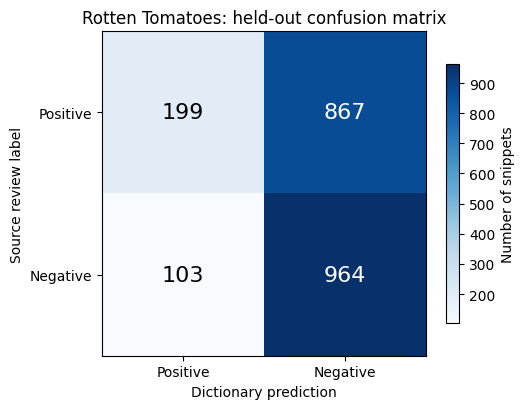

In [13]:
import matplotlib.pyplot as plt

matrix = [
    [rt_metrics["TP"], rt_metrics["FN"]],
    [rt_metrics["FP"], rt_metrics["TN"]],
]

fig, ax = plt.subplots(figsize=(5.3, 4.2))
image = ax.imshow(matrix, cmap="Blues")
ax.set_xticks([0, 1], ["Positive", "Negative"])
ax.set_yticks([0, 1], ["Positive", "Negative"])
ax.set_xlabel("Dictionary prediction")
ax.set_ylabel("Source review label")
ax.set_title("Rotten Tomatoes: held-out confusion matrix")

for row_index, row in enumerate(matrix):
    for column_index, value in enumerate(row):
        ax.text(column_index, row_index, value, ha="center", va="center", fontsize=16,
                color="white" if value > max(map(max, matrix)) / 2 else "black")

fig.colorbar(image, ax=ax, shrink=0.8, label="Number of snippets")
fig.tight_layout()
plt.show()


## A precision-recall curve for the sentiment dictionary

The integer sentiment score ranks snippets from more negative to more positive. Each possible score threshold creates a different positive-negative classification. With the larger Rotten Tomatoes test set, we can plot the resulting precision-recall trade-off.


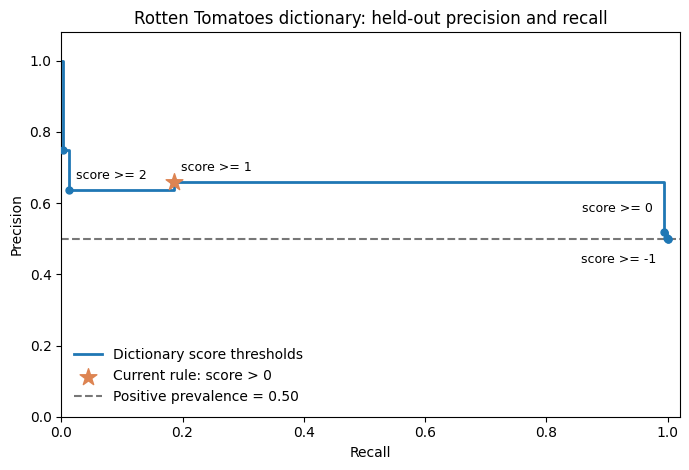

In [14]:
import matplotlib.pyplot as plt

curve_points = []
for threshold in sorted({row["dictionary_score"] for row in rt_test}, reverse=True):
    tp = sum(row["dictionary_score"] >= threshold and row["reference_label"] == 1 for row in rt_test)
    fp = sum(row["dictionary_score"] >= threshold and row["reference_label"] == 0 for row in rt_test)
    fn = sum(row["dictionary_score"] < threshold and row["reference_label"] == 1 for row in rt_test)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    curve_points.append((threshold, precision, recall))

# The conventional endpoint (recall=0, precision=1) represents predicting no positives.
# Precision at that endpoint is a plotting convention, not an observed estimate.
recalls = [0.0] + [point[2] for point in curve_points]
precisions = [1.0] + [point[1] for point in curve_points]
prevalence = sum(row["reference_label"] for row in rt_test) / len(rt_test)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.step(recalls, precisions, where="post", color="#1f77b4", linewidth=2, label="Dictionary score thresholds")
ax.scatter(recalls[1:], precisions[1:], color="#1f77b4", s=25, zorder=3)
for threshold, precision, recall in curve_points:
    if threshold in (-1, 0, 1, 2):
        offset = (-8, 14) if threshold == 0 else (-8, -18) if threshold == -1 else (5, 8)
        ax.annotate(f"score >= {threshold}", (recall, precision),
                    xytext=offset, textcoords="offset points", fontsize=9,
                    ha="right" if threshold <= 0 else "left")
ax.scatter(rt_metrics["recall"], rt_metrics["precision"],
           marker="*", s=160, color="#dd8452", zorder=4, label="Current rule: score > 0")
ax.axhline(prevalence, color="#777777", linestyle="--",
           label=f"Positive prevalence = {prevalence:.2f}")
ax.set(xlim=(0, 1.02), ylim=(0, 1.08), xlabel="Recall", ylabel="Precision",
       title="Rotten Tomatoes dictionary: held-out precision and recall")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
plt.show()


## What drives baseline errors? Rotten Tomatoes

For false positives, positive dictionary terms push the score toward a positive prediction. For false negatives, negative dictionary terms push it toward a negative prediction. We count the development passages containing each term, so repeating a word in one snippet does not make it dominate the chart.

These charts diagnose the rule, rather than prove that a particular word caused an error. Positive language may be negated, ironic, or outweighed by an overall criticism. False negatives with no dictionary matches cannot be explained by negative terms.


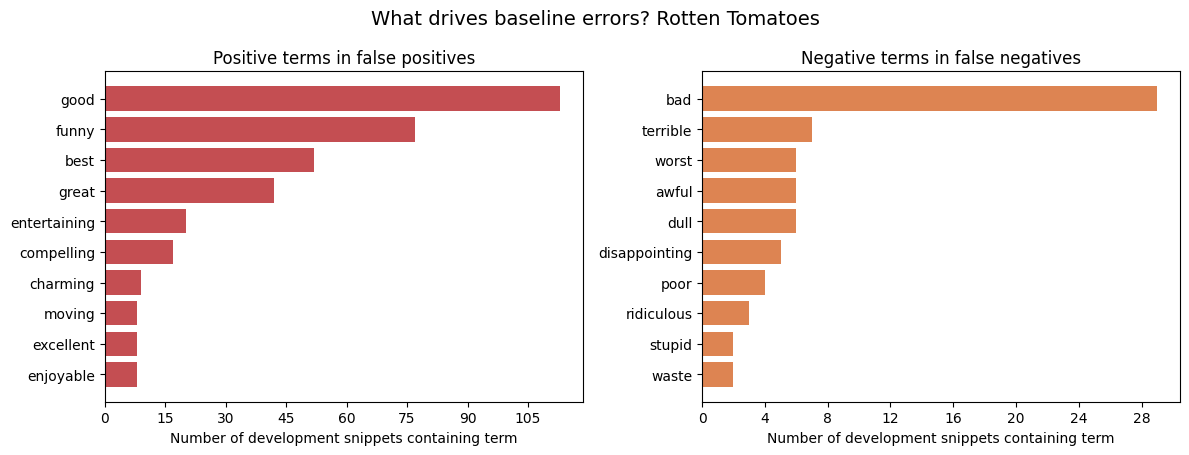

False negatives with no sentiment dictionary matches: 3381 of 3451


In [15]:
from collections import Counter
import matplotlib.pyplot as plt

rt_false_positives = [
    row for row in rt_development
    if row["sentiment_dictionary"] == 1 and row["reference_label"] == 0
]
rt_false_negatives = [
    row for row in rt_development
    if row["sentiment_dictionary"] == 0 and row["reference_label"] == 1
]

def term_passage_counts(subset, vocabulary):
    return Counter(
        term for row in subset
        for term in set(re.findall(r"[a-z]+", row["text"].lower())) & vocabulary
    )

positive_error_terms = term_passage_counts(rt_false_positives, positive_terms)
negative_error_terms = term_passage_counts(rt_false_negatives, negative_terms)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, counts, title, colour in [
    (axes[0], positive_error_terms, "Positive terms in false positives", "#c44e52"),
    (axes[1], negative_error_terms, "Negative terms in false negatives", "#dd8452"),
]:
    items = counts.most_common(10)[::-1]
    ax.barh([term for term, count in items], [count for term, count in items], color=colour)
    ax.set_title(title)
    ax.set_xlabel("Number of development snippets containing term")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.suptitle("What drives baseline errors? Rotten Tomatoes", fontsize=14)
fig.tight_layout()
plt.show()

zero_match_false_negatives = sum(
    not (set(re.findall(r"[a-z]+", row["text"].lower())) & (positive_terms | negative_terms))
    for row in rt_false_negatives
)
print(f"False negatives with no sentiment dictionary matches: {zero_match_false_negatives} of {len(rt_false_negatives)}")


## Inspect what the dictionary cannot see

Look for negation, sarcasm, domain-specific language, and snippets whose review-level label does not fit the isolated sentence. These are different kinds of disagreement, and not all of them should be solved by simply adding another word to the list.


In [16]:
zero_score_examples = [row for row in rt_test if row["dictionary_score"] == 0]
for row in zero_score_examples[:12]:
    label = "positive" if row["reference_label"] else "negative"
    print(f"[{label:8}] {row['text']}")


[negative] simplistic , silly and tedious . 
[negative] the story is also as unoriginal as they come , already having been recycled more times than i'd care to count . 
[negative] a sentimental mess that never rings true . 
[negative] the execution is so pedestrian that the most positive comment we can make is that rob schneider actually turns in a pretty convincing performance as a prissy teenage girl . 
[negative] the party scenes deliver some tawdry kicks . the rest of the film . . . is dudsville . 
[negative] somewhere in the middle , the film compels , as demme experiments he harvests a few movie moment gems , but the field of roughage dominates . 
[negative] i didn't laugh . i didn't smile . i survived . 
[negative] though the opera itself takes place mostly indoors , jacquot seems unsure of how to evoke any sort of naturalism on the set . 
[negative] stinks from start to finish , like a wet burlap sack of gloom . 
[negative] when seagal appeared in an orange prison jumpsuit , i 

## Try it with the sentiment data

1. Read several errors before adding any terms.
2. Add a small number of terms using the development split only.
3. Recalculate performance on the test split once.
4. Explain whether an error reflects a weak dictionary, a review-level label, or the limits of isolated snippets.


## Try it

1. Change the expanded rule to prioritize **precision**. Which terms or phrases would you remove?
2. Change it to prioritize **recall**. What additional wording would you include?
3. Revise only with the development set, then check the held-out test set once. Does the rule still follow the codebook?
4. Choose another concept in the State of the Union corpus. Sketch a codebook and a search strategy before writing any pattern.
